# บทที่ 5 · แท่ง จุด ฮิสโตแกรม และวงกลม

เลือกกราฟผิดชนิด = สื่อสารผิดทาง ตารางนี้คือคู่มือเลือกกราฟที่ควรจำติดตัว (โผล่ในข้อสอบบ่อย!):

| คำถามที่อยากรู้ | กราฟที่เหมาะ | คำสั่ง |
|---|---|---|
| แนวโน้มเปลี่ยนไปตามเวลาไหม | เส้น | `plt.plot()` |
| หมวดไหนมาก/น้อยกว่ากัน | แท่ง | `plt.bar()` / `plt.barh()` |
| สองตัวแปรสัมพันธ์กันไหม | จุด (scatter) | `plt.scatter()` |
| ค่ากระจายตัวแค่ไหน | ฮิสโตแกรม | `plt.hist()` |
| แต่ละส่วนคิดเป็นกี่เปอร์เซ็นต์ | วงกลม | `plt.pie()` |

## 🗂️ การ์ดข้อมูล: coffee_sales_nyc_2023.csv.gz (ธุรกรรมร้านกาแฟ 3 สาขา ในนิวยอร์ก)

| รายการ | รายละเอียด |
|---|---|
| **ที่มา** | Coffee Shop Sales — ชุดข้อมูลฝึกวิเคราะห์มาตรฐานสากลจาก Maven Analytics จำลองธุรกรรม POS ของร้านกาแฟ "Maven Roasters" 3 สาขาในนิวยอร์ก ช่วง 1 ม.ค. – 30 มิ.ย. 2023 (โครงสร้างเหมือนข้อมูล POS ของร้านจริงทุกประการ) |
| **สาขา** | Astoria · Hell's Kitchen · Lower Manhattan |
| **จำนวนแถว** | 149,116 ธุรกรรม (เร็วกว่าหน่วยก่อน ๆ เพราะ pandas ออกแบบมาเพื่อข้อมูลใหญ่) |
| **คอลัมน์** | `transaction_id` รหัสธุรกรรม · `transaction_date` วันที่ · `transaction_time` เวลา · `transaction_qty` จำนวนที่ซื้อ · `store_id`/`store_location` สาขา · `product_id`/`product_category`/`product_type`/`product_detail` ข้อมูลสินค้า 3 ระดับ · `unit_price` ราคาต่อชิ้น (ดอลลาร์) |
| **หมวดสินค้า** | Coffee · Tea · Bakery · Drinking Chocolate · Flavours · Loose Tea · Coffee beans · Package Chocolate |
| **ค่าหาย** | ไม่มีเลย (ข้อมูลจากเครื่อง POS จึงครบถ้วน) |
| **หมายเหตุ** | ไฟล์บีบอัด `.gz` — pandas เปิดได้ตรง ๆ ด้วย `pd.read_csv()` ไม่ต้องแตกไฟล์ เพราะข้อมูลจริงในบริษัทมักใหญ่และถูกบีบอัดเสมอ |

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

coffee = pd.read_csv("data/coffee_sales_nyc_2023.csv.gz")

print(coffee.head())
print()
print("ขนาดข้อมูล:", coffee.shape)
print("ค่าหายทั้งตาราง:", coffee.isna().sum().sum())

# เพิ่มคอลัมน์รายได้ต่อธุรกรรม = จำนวน x ราคาต่อชิ้น
coffee["revenue"] = coffee["transaction_qty"] * coffee["unit_price"]
print("เพิ่มคอลัมน์ revenue เรียบร้อย")

   transaction_id transaction_date transaction_time  transaction_qty  \
0               1       01-01-2023         07:06:11                2   
1               2       01-01-2023         07:08:56                2   
2               3       01-01-2023         07:14:04                2   
3               4       01-01-2023         07:20:24                1   
4               5       01-01-2023         07:22:41                2   

   store_id   store_location  product_id  unit_price    product_category  \
0         5  Lower Manhattan          32         3.0              Coffee   
1         5  Lower Manhattan          57         3.1                 Tea   
2         5  Lower Manhattan          59         4.5  Drinking Chocolate   
3         5  Lower Manhattan          22         2.0              Coffee   
4         5  Lower Manhattan          57         3.1                 Tea   

            product_type               product_detail  
0  Gourmet brewed coffee                  Ethiopia Rg 

## กราฟแท่ง — เปรียบเทียบระหว่างหมวด

"หมวดสินค้าไหนขายได้ถึงแก้วมากที่สุด?" — นับจำนวนแก้วรวมของแต่ละหมวดด้วย `groupby().sum()` แล้ววาดแท่งแนวตั้ง

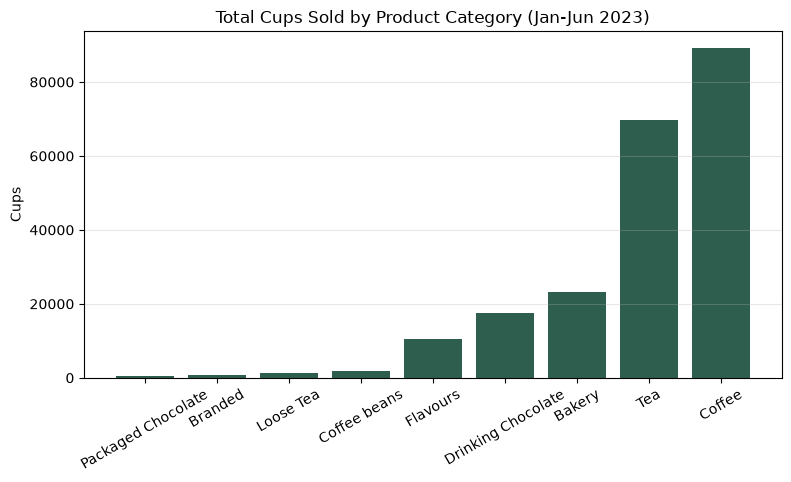

In [4]:
# จำนวนแก้วรวมแยกตามหมวดสินค้า
cups_by_cat = coffee.groupby("product_category")["transaction_qty"].sum().sort_values()

plt.figure(figsize=(9, 4.5))
plt.bar(cups_by_cat.index, cups_by_cat.values, color="#2E5E4E")
plt.title("Total Cups Sold by Product Category (Jan-Jun 2023)")
plt.ylabel("Cups")
plt.xticks(rotation=30)
plt.grid(True, axis="y", alpha=0.3)
plt.show()

รายการเยอะและชื่อยาว → แท่งแนวตั้งจะเบียดกันจนอ่านไม่ออก วิธีแก้คือ **แท่งแนวนอน** (`barh`) แล้ว**เรียงค่าด้วย pandas ก่อน** เทคนิคที่ใช้งานจริงบ่อยมาก

คราวนี้ดูระดับสินค้า (`product_detail`) ว่า 10 อันดับสินค้าที่ทำรายได้สูงสุดคืออะไรบ้าง

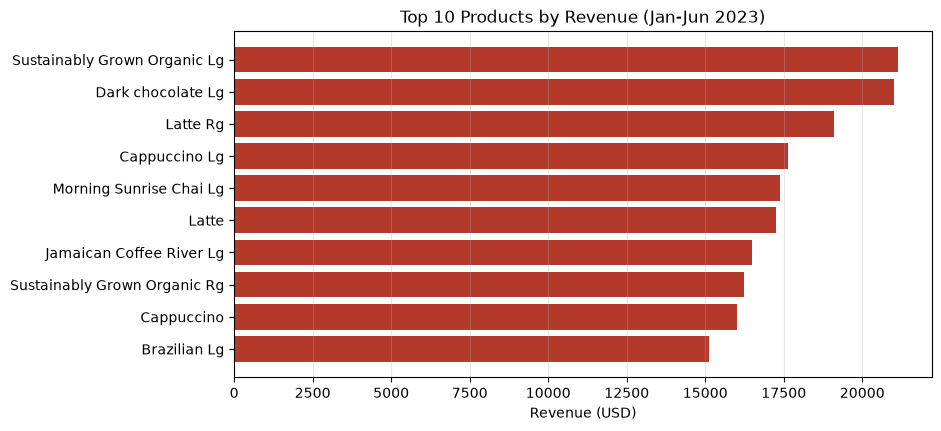

In [5]:
# Top 10 สินค้าที่ทำรายได้สูงสุด -> แท่งแนวนอน เรียงจากน้อยไปมากก่อนวาด
top_rev = coffee.groupby("product_detail")["revenue"].sum().sort_values(ascending=False).head(10)
top_rev = top_rev.sort_values()          # กลับด้านให้ตัวใหญ่สุดอยู่บนสุดของ barh

plt.figure(figsize=(9, 4.5))
plt.barh(top_rev.index, top_rev.values, color="#B33A2B")
plt.title("Top 10 Products by Revenue (Jan-Jun 2023)")
plt.xlabel("Revenue (USD)")
plt.grid(True, axis="x", alpha=0.3)
plt.show()

## กราฟจุด — มองหาความสัมพันธ์

คำถามวิเคราะห์จริง: *"เดือนที่ร้อน ฝนจะตกมากหรือน้อย?"* — เอาข้อมูลอากาศจริงมาตอบ: แกน x = อุณหภูมิเฉลี่ยรายเดือนของเชียงใหม่ แกน y = ปริมาณฝน แล้วดูแบบแผนของจุด

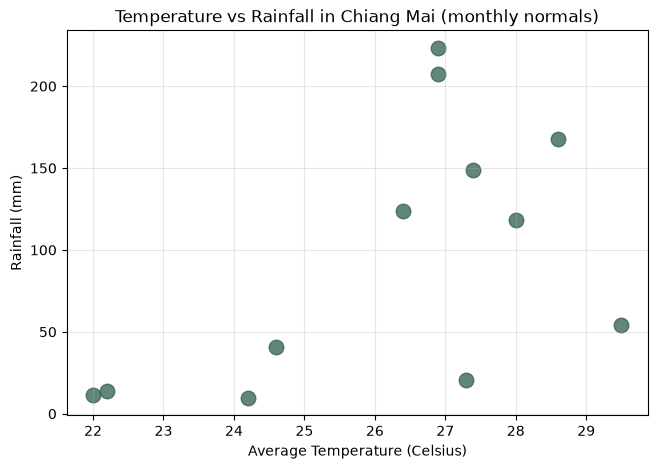

In [6]:
climate = pd.read_csv("data/thai_monthly_climate_1991_2020.csv")

plt.figure(figsize=(7.5, 5))
plt.scatter(climate["cm_mean_c"], climate["cm_rain_mm"], s=110, alpha=0.75, color="#2E5E4E")
plt.title("Temperature vs Rainfall in Chiang Mai (monthly normals)")
plt.xlabel("Average Temperature (Celsius)")
plt.ylabel("Rainfall (mm)")
plt.grid(True, alpha=0.3)
plt.show()

# พบไหม? จุดฝนมาก (>100 มม.) กระจุกอยู่ฝั่งขวา = อุณหภูมิสูง
# เพราะเดือนความร้อน (พ.ค.-ต.ค.) พอดีเป็นฤดูฝนของไทย นี่คือ "ความสัมพันธ์" ที่ scatter มองให้เห็น

## ฮิสโตแกรม — ข้อมูลกระจายตัวแค่ไหน

ฮิสโตแกรมจะ "ตัก"ค่าเข้าถัง (bins) แล้วนับว่าแต่ละถังมีกี่ค่า — เห็นค่าเฉลี่ย ความกว้าง และค่าที่ผิดปกติในภาพเดียว

คราวนี้ดูการกระจายของ **ยอดซื้อต่อธุรกรรม** จากข้อมูลกาแฟ 149,116 รายการ

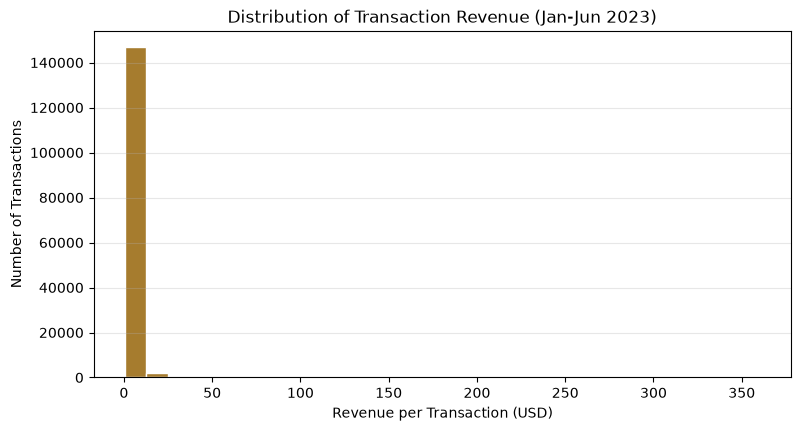

In [7]:
plt.figure(figsize=(9, 4.5))
plt.hist(coffee["revenue"], bins=30, color="#A67C2E", edgecolor="white")
plt.title("Distribution of Transaction Revenue (Jan-Jun 2023)")
plt.xlabel("Revenue per Transaction (USD)")
plt.ylabel("Number of Transactions")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

# ลองตอบ: ธุรกรรมส่วนใหญ่ (แท่งสูงสุด) มียอดประมาณกี่ดอลลาร์?

## `subplots` + กราฟวงกลม — สัดส่วนและการวางหลายกราฟ

`plt.subplots(แถว, คอลัมน์)` คืนผืนผ้าใบ (`fig`) และช่องวาง (`ax`) หลายช่อง — ใช้เมื่อต้องการวางกราฟเคียงกันเพื่อเปรียบเทียบ สังเกตว่าคำสั่งตกแต่งเป็นของช่อง (`ax[0].set_title()`) ไม่ใช่ plt ตรง ๆ

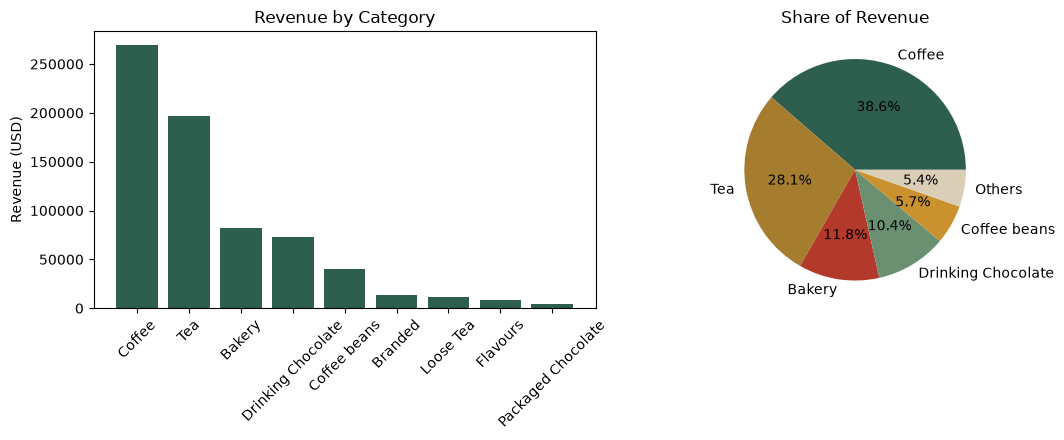

In [8]:
# เทียบ 2 มุมมองของหมวดสินค้า: รายได้แบบแท่ง vs สัดส่วนแบบวงกลม
rev_by_cat = coffee.groupby("product_category")["revenue"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.5))

ax[0].bar(rev_by_cat.index, rev_by_cat.values, color="#2E5E4E")
ax[0].set_title("Revenue by Category")
ax[0].set_ylabel("Revenue (USD)")
ax[0].tick_params(axis="x", rotation=45)

top5 = rev_by_cat.head(5)
others = rev_by_cat.iloc[5:].sum()
pie_data = pd.concat([top5, pd.Series({"Others": others})])
ax[1].pie(pie_data.values, labels=pie_data.index, autopct="%.1f%%",
          colors=["#2E5E4E", "#A67C2E", "#B33A2B", "#6B8F71", "#C9922E", "#DACFB6"])
ax[1].set_title("Share of Revenue")

plt.tight_layout()
plt.show()

## 🎯 ภารกิจบทที่ 5 (ส่งคำตอบใน Moodle)

จากกราฟและตารางที่เพิ่งทำ **หมวดสินค้า (product_category) ที่ทำรายได้รวมสูงสุดคือหมวดอะไร**

*ใบ้: `coffee.groupby("product_category")["revenue"].sum().idxmax()`*

In [9]:
# ภารกิจ 5: หมวดสินค้าที่รายได้สูงสุด
best_cat = coffee.groupby("product_category")["revenue"].sum().idxmax()
print("หมวดสินค้ารายได้สูงสุด =", best_cat)
print("คำตอบภารกิจบทที่ 5 =", best_cat)

หมวดสินค้ารายได้สูงสุด = Coffee
คำตอบภารกิจบทที่ 5 = Coffee
